<a href="https://colab.research.google.com/github/AmalKhairalla/OPL-Insights/blob/main/DS330_P1_Baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS330 Project Part 1: Train and Tune a Deep Neural Network

## Predicting Deadlift Performance Using OpenPowerlifting Data

### Project Overview

This project investigates how different training configurations affect the performance of deep neural networks on a tabular regression task.

We use competition results from the Powerlifting Federation of Russia (FPR), focusing on Single-ply equipment and full-power (SBD) competitions.

**Prediction target:** Best3DeadliftKg

**Input features:**
- Age
- Sex
- BodyweightKg
- Best3SquatKg
- Best3BenchKg

The dataset contains 81,957 competition records before final preprocessing.

### Project Objectives

1. Prepare and preprocess the dataset while preventing data leakage.
2. Establish a linear regression baseline.
3. Train a deep neural network using PyTorch.
4. Conduct at least 30 controlled experiments across at least four training topics.
5. Analyze training behavior, generalization, and model performance.
6. Select the best configuration using validation results and evaluate it once on the test set.

The dataset-selection process and preliminary experiments are documented in a separate exploratory notebook.

**Data source:** https://data.openpowerlifting.org/

Notebook structure

1/11 sections completed

[ ] 1. Introduction

Describe the prediction task, data source, features and target.


[x] 2. Load the dataset

Read the saved FPR dataset and verify its size and columns.


[ ] 3. Small EDA

Check missing values, distributions, correlations, categorical counts and basic data quality.


[ ] 4. Data preparation

Select predictors, handle missing values and create grouped splits.


[ ] 5. Encoding and scaling

One-hot encode Sex, impute Age and standardize numerical inputs using training data only.


[ ] 6. Linear baseline

Train linear regression and report train/validation MSE.


[ ] 7. Baseline neural network

Build a PyTorch network and plot training/validation loss.


[ ] 8. 30 controlled experiments

Investigate at least four topics with one setting changed at a time.


[ ] 9. Results analysis

Compare performance, runtime, stability, overfitting and underfitting.


[ ] 10. Final evaluation

Select the model using validation MSE and evaluate once on the untouched test set.


[ ] 11. Conclusion

Explain the findings, limitations, what to improve and AI tools used.

##Load the dataset

In [5]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import random

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error

SEED = 42

np.random.seed(SEED)
random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch:", torch.__version__)
print("Device:", device)


PyTorch: 2.14.1+cu130
Device: cuda


In [6]:

url = (
    "https://raw.githubusercontent.com/"
    "AmalKhairalla/OPL-Insights/main/"
    "data/FPR_SinglePly_SBD.csv.gz"
)

df = pd.read_csv(url, compression="gzip")

print("Dataset shape:", df.shape)
display(df.head())

assert len(df) == 81957


Dataset shape: (81957, 11)


,Name,Sex,Date,Age,BodyweightKg,Best3SquatKg,Best3BenchKg,Best3DeadliftKg,Federation,Equipment,Event
0,Ekaterina Korobova,F,2012-02-10,14.5,41.90,62.5,35.0,70.0,FPR,Single-ply,SBD
1,Kseniya Zorkina,F,2012-02-10,17.5,46.60,77.5,30.0,82.5,FPR,Single-ply,SBD
2,Anna Prokhorova,F,2012-02-10,17.5,48.00,87.5,40.0,90.0,FPR,Single-ply,SBD
3,Natalya Shabusova,F,2012-02-10,16.5,56.75,110.0,62.5,115.0,FPR,Single-ply,SBD
4,Darya Shemyakina,F,2012-02-10,17.5,54.10,67.5,42.5,90.0,FPR,Single-ply,SBD


##EDA

In [8]:
print("Dataset shape:", df.shape)

print("\nColumn types:")
display(df.dtypes.to_frame("Type"))



Dataset shape: (81957, 11)

Column types:


,Type
Name,object
Sex,object
Date,object
Age,float64
BodyweightKg,float64
Best3SquatKg,float64
Best3BenchKg,float64
Best3DeadliftKg,float64
Federation,object
Equipment,object


In [9]:
missing_summary = pd.DataFrame({
    "Missing count": df.isna().sum(),
    "Missing %": (df.isna().mean() * 100).round(2)
})

display(missing_summary)


,Missing count,Missing %
Name,0,0.00
Sex,0,0.00
Date,0,0.00
Age,1016,1.24
BodyweightKg,0,0.00
Best3SquatKg,0,0.00
Best3BenchKg,0,0.00
Best3DeadliftKg,0,0.00
Federation,0,0.00
Equipment,0,0.00


In [11]:
print("\nSex distribution:")
display(df["Sex"].value_counts())


Sex distribution:


,count
Sex,
M,60535
F,21422


In [12]:
print("\nNumeric summary:")
display(df.describe())


Numeric summary:


,Age,BodyweightKg,Best3SquatKg,Best3BenchKg,Best3DeadliftKg
count,80941.000000,81957.000000,81957.000000,81957.000000,81957.000000
mean,23.424846,77.243529,202.898677,129.837203,200.197302
std,8.182679,21.414267,78.562749,58.027942,67.816476
min,7.500000,25.750000,20.000000,17.500000,25.000000
25%,17.500000,59.750000,140.000000,80.000000,145.000000
50%,21.500000,74.000000,200.000000,127.500000,200.000000
75%,26.500000,90.050000,265.000000,175.000000,252.500000
max,79.000000,260.000000,482.500000,377.500000,405.000000


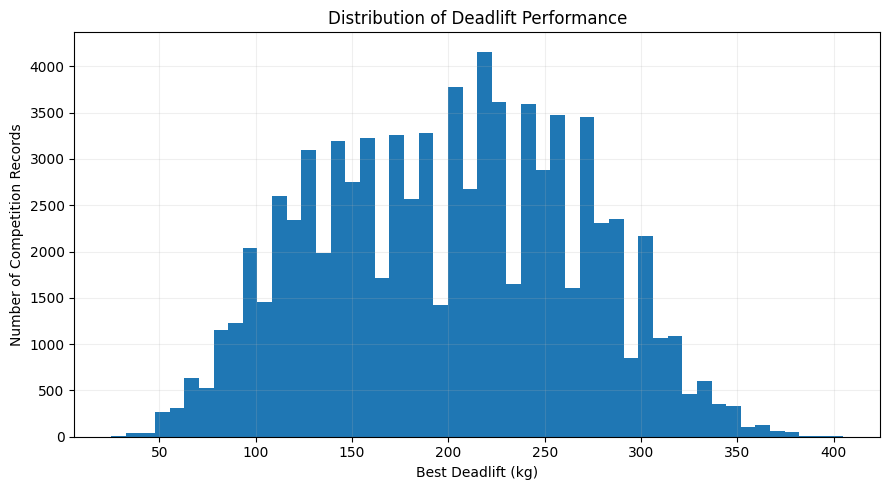

In [13]:
plt.figure(figsize=(9, 5))

plt.hist(
    df["Best3DeadliftKg"],
    bins=50
)

plt.title("Distribution of Deadlift Performance")
plt.xlabel("Best Deadlift (kg)")
plt.ylabel("Number of Competition Records")

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


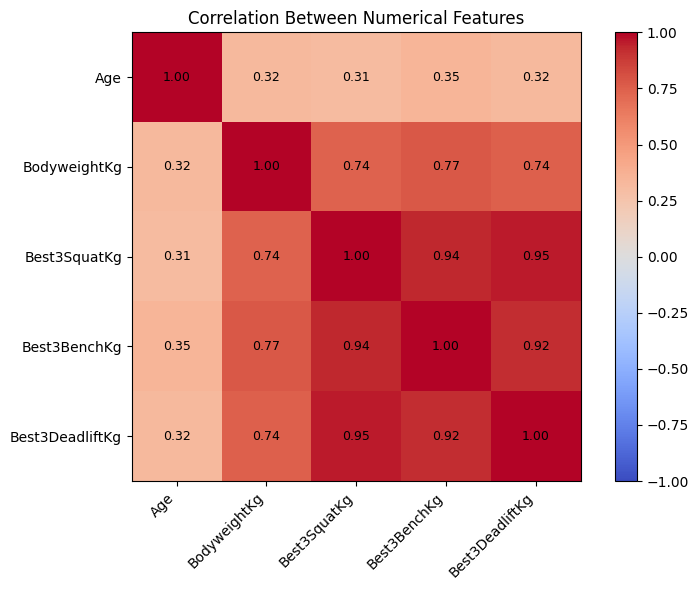

In [14]:

features_numeric = [
    "Age",
    "BodyweightKg",
    "Best3SquatKg",
    "Best3BenchKg",
    "Best3DeadliftKg"
]

correlation = df[features_numeric].corr()

fig, ax = plt.subplots(figsize=(8, 6))

im = ax.imshow(
    correlation,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(features_numeric)))
ax.set_yticks(range(len(features_numeric)))

ax.set_xticklabels(
    features_numeric,
    rotation=45,
    ha="right"
)
ax.set_yticklabels(features_numeric)

for i in range(len(features_numeric)):
    for j in range(len(features_numeric)):
        ax.text(
            j, i,
            f"{correlation.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=9
        )

plt.colorbar(im, ax=ax)
plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()


##Data preparation

In [15]:

# Normalize names for grouping
df = df.reset_index(drop=True).copy()

groups = (
    df["Name"]
    .astype("string")
    .str.strip()
    .str.casefold()
)

assert groups.notna().all()
assert groups.ne("").all()

# First reserve test groups
split_test = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=42
)

trainval_idx, test_idx = next(
    split_test.split(df, groups=groups)
)

# Split remaining groups into train and validation
split_val = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15 / 0.85,
    random_state=43
)

train_rel, val_rel = next(
    split_val.split(
        df.iloc[trainval_idx],
        groups=groups.iloc[trainval_idx]
    )
)

train_idx = trainval_idx[train_rel]
val_idx = trainval_idx[val_rel]

train_df = df.iloc[train_idx].copy()
val_df = df.iloc[val_idx].copy()
test_df = df.iloc[test_idx].copy()

# Verify zero name overlap
train_names = set(groups.iloc[train_idx])
val_names = set(groups.iloc[val_idx])
test_names = set(groups.iloc[test_idx])

assert train_names.isdisjoint(val_names)
assert train_names.isdisjoint(test_names)
assert val_names.isdisjoint(test_names)

print("No recorded-name overlap!")

for name, frame in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(
        name,
        len(frame),
        f"({len(frame)/len(df)*100:.2f}%)"
    )


No recorded-name overlap!
Training 56908 (69.44%)
Validation 12571 (15.34%)
Test 12478 (15.23%)


In [16]:

numeric_features = [
    "Age",
    "BodyweightKg",
    "Best3SquatKg",
    "Best3BenchKg"
]

categorical_features = ["Sex"]

target = "Best3DeadliftKg"

features = numeric_features + categorical_features

# Separate predictors and target
X_train = train_df[features]
X_val = val_df[features]

y_train = train_df[target]
y_val = val_df[target]

# Numeric preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Numeric + categorical preprocessing
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("sex", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ), categorical_features)
])

# Fit ONLY on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Reuse training transformations
X_val_processed = preprocessor.transform(X_val)

print("Training shape:", X_train_processed.shape)
print("Validation shape:", X_val_processed.shape)

print("\nEncoded feature names:")
print(preprocessor.get_feature_names_out())


Training shape: (56908, 6)
Validation shape: (12571, 6)

Encoded feature names:
['numeric__Age' 'numeric__BodyweightKg' 'numeric__Best3SquatKg'
 'numeric__Best3BenchKg' 'sex__Sex_F' 'sex__Sex_M']


In [24]:

import pandas as pd

# Use the existing split dataframes
# No need to redo splitting or preprocessing

split_data = df.copy()

# Verify every record belongs to exactly one split
assert train_df.index.is_unique
assert val_df.index.is_unique
assert test_df.index.is_unique

assert set(train_df.index).isdisjoint(val_df.index)
assert set(train_df.index).isdisjoint(test_df.index)
assert set(val_df.index).isdisjoint(test_df.index)

assert (
    set(train_df.index)
    | set(val_df.index)
    | set(test_df.index)
) == set(split_data.index)

# Attach labels to existing records
split_data["Split"] = ""

split_data.loc[train_df.index, "Split"] = "train"
split_data.loc[val_df.index, "Split"] = "validation"
split_data.loc[test_df.index, "Split"] = "test"

# Save the fixed dataset
file_path = "/content/FPR_SinglePly_fixed_split.csv.gz"

split_data.to_csv(
    file_path,
    index=False,
    compression="gzip"
)

print("Saved successfully!")
print(split_data["Split"].value_counts())


Saved successfully!
Split
train         56908
validation    12571
test          12478
Name: count, dtype: int64


##Baseline Models — Linear Regression vs. Deep Neural Network

###Linear Regression Baseline

In [17]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import numpy as np

# Train linear regression
linear_model = LinearRegression()

linear_model.fit(
    X_train_processed,
    y_train
)

# Predictions
linear_train_pred = linear_model.predict(
    X_train_processed
)

linear_val_pred = linear_model.predict(
    X_val_processed
)

# Calculate MSE in original kg scale
linear_train_mse = mean_squared_error(
    y_train, linear_train_pred
)

linear_val_mse = mean_squared_error(
    y_val, linear_val_pred
)

print("Linear Regression Baseline")
print("--------------------------")
print(f"Training MSE: {linear_train_mse:.2f} kg²")
print(f"Validation MSE: {linear_val_mse:.2f} kg²")


Linear Regression Baseline
--------------------------
Training MSE: 341.94 kg²
Validation MSE: 358.80 kg²


###PyTorch Neural Network Baseline

In [18]:

import torch
import numpy as np
import random

from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Standardize target using training data only
y_scaler = StandardScaler()

y_train_scaled = y_scaler.fit_transform(
    np.asarray(y_train).reshape(-1, 1)
)

# Convert inputs to tensors
Xtr = torch.tensor(
    X_train_processed,
    dtype=torch.float32
).to(device)

Xva = torch.tensor(
    X_val_processed,
    dtype=torch.float32
).to(device)

ytr = torch.tensor(
    y_train_scaled,
    dtype=torch.float32
).to(device)

train_loader = DataLoader(
    TensorDataset(Xtr, ytr),
    batch_size=64,
    shuffle=True
)

print("Input features:", Xtr.shape[1])
print("Device:", device)


Input features: 6
Device: cuda


In [19]:

import time

# Define baseline neural network
baseline_nn = nn.Sequential(
    nn.Linear(Xtr.shape[1], 64),
    nn.ReLU(),
    nn.Linear(64, 64),
    nn.ReLU(),
    nn.Linear(64, 64),
    nn.ReLU(),
    nn.Linear(64, 1)
).to(device)

optimizer = torch.optim.SGD(
    baseline_nn.parameters(),
    lr=0.01
)

criterion = nn.MSELoss()

nn_train_losses = []
nn_val_losses = []

start_time = time.perf_counter()

# Fixed 30 epochs for a controlled baseline
for epoch in range(30):

    baseline_nn.train()

    for xb, yb in train_loader:
        optimizer.zero_grad()

        predictions = baseline_nn(xb)
        loss = criterion(predictions, yb)

        loss.backward()
        optimizer.step()

    # Evaluate on original target scale
    baseline_nn.eval()

    with torch.no_grad():
        train_scaled = baseline_nn(Xtr).cpu().numpy()
        val_scaled = baseline_nn(Xva).cpu().numpy()

    train_pred = y_scaler.inverse_transform(
        train_scaled
    ).ravel()

    val_pred = y_scaler.inverse_transform(
        val_scaled
    ).ravel()

    train_mse = mean_squared_error(
        y_train, train_pred
    )

    val_mse = mean_squared_error(
        y_val, val_pred
    )

    nn_train_losses.append(train_mse)
    nn_val_losses.append(val_mse)

    print(
        f"Epoch {epoch+1:02d}/30 | "
        f"Train MSE: {train_mse:.2f} | "
        f"Val MSE: {val_mse:.2f}"
    )

nn_time = time.perf_counter() - start_time

print("\nBaseline NN completed!")
print(f"Final Train MSE: {nn_train_losses[-1]:.2f}")
print(f"Final Val MSE: {nn_val_losses[-1]:.2f}")
print(f"Training time: {nn_time:.2f} seconds")


Epoch 01/30 | Train MSE: 338.48 | Val MSE: 349.36
Epoch 02/30 | Train MSE: 323.06 | Val MSE: 335.31
Epoch 03/30 | Train MSE: 316.97 | Val MSE: 329.32
Epoch 04/30 | Train MSE: 315.11 | Val MSE: 327.94
Epoch 05/30 | Train MSE: 318.21 | Val MSE: 329.84
Epoch 06/30 | Train MSE: 312.80 | Val MSE: 326.28
Epoch 07/30 | Train MSE: 317.59 | Val MSE: 334.97
Epoch 08/30 | Train MSE: 310.63 | Val MSE: 324.64
Epoch 09/30 | Train MSE: 311.91 | Val MSE: 327.88
Epoch 10/30 | Train MSE: 309.95 | Val MSE: 324.12
Epoch 11/30 | Train MSE: 313.25 | Val MSE: 326.19
Epoch 12/30 | Train MSE: 311.63 | Val MSE: 325.38
Epoch 13/30 | Train MSE: 309.62 | Val MSE: 324.68
Epoch 14/30 | Train MSE: 310.08 | Val MSE: 325.24
Epoch 15/30 | Train MSE: 308.87 | Val MSE: 322.66
Epoch 16/30 | Train MSE: 313.38 | Val MSE: 330.27
Epoch 17/30 | Train MSE: 310.48 | Val MSE: 326.12
Epoch 18/30 | Train MSE: 309.17 | Val MSE: 322.88
Epoch 19/30 | Train MSE: 311.38 | Val MSE: 324.63
Epoch 20/30 | Train MSE: 307.98 | Val MSE: 322.80


,Model,Train MSE,Validation MSE
0,Linear Regression,341.94,358.8
1,Baseline Neural Network,309.05,323.0


NN improvement over Linear: 9.98%


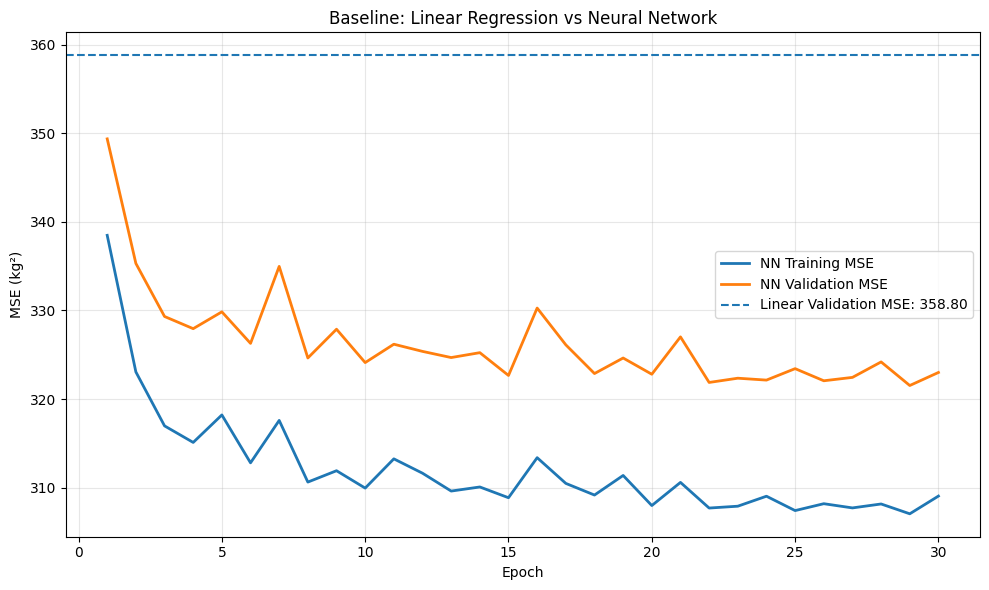

In [20]:

import pandas as pd
import matplotlib.pyplot as plt

# Results table
baseline_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Baseline Neural Network"
    ],
    "Train MSE": [
        linear_train_mse,
        nn_train_losses[-1]
    ],
    "Validation MSE": [
        linear_val_mse,
        nn_val_losses[-1]
    ]
})

display(baseline_results.round(2))

improvement = (
    (linear_val_mse - nn_val_losses[-1])
    / linear_val_mse * 100
)

print(f"NN improvement over Linear: {improvement:.2f}%")

# Learning curves
plt.figure(figsize=(10, 6))

epochs = range(1, len(nn_train_losses) + 1)

plt.plot(
    epochs,
    nn_train_losses,
    label="NN Training MSE",
    linewidth=2
)

plt.plot(
    epochs,
    nn_val_losses,
    label="NN Validation MSE",
    linewidth=2
)

plt.axhline(
    linear_val_mse,
    linestyle="--",
    label=f"Linear Validation MSE: {linear_val_mse:.2f}"
)

plt.xlabel("Epoch")
plt.ylabel("MSE (kg²)")
plt.title("Baseline: Linear Regression vs Neural Network")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Baseline Results and Observations

The baseline neural network achieved a validation MSE of **323.00 kg²**, compared with **358.80 kg²** for linear regression, representing a **9.98% reduction in validation MSE**.

Both training and validation errors decreased during training, indicating that the neural network learned useful predictive relationships. Validation loss fluctuated but generally stabilized during later epochs.

The final training and validation MSE values were 309.05 kg² and 323.00 kg², respectively, indicating a relatively small generalization gap and no strong evidence of severe overfitting.

These results establish the baseline for subsequent experiments investigating learning rate, optimizer, batch size, network architecture, and loss function.